# 05 - Which variables does the network use?
Wine Quality dataset (red and white wines), regression of the quality score

Neural networks are often called "black boxes" because their weights are hard to interpret.
A simple way to see which inputs are important is **permutation importance**, the same method used
for the random forest in the ML report: we shuffle one variable in the test fold, so that it does
not contain information any more, and measure how much the RMSE increases. If the network does not
use the variable, the RMSE does not change.

We use the medium network (64-32), the same 5 outer folds and 10 repetitions per variable, exactly
as in the ML report, so the two importances can be compared.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, r2_score, f1_score, accuracy_score,
                             recall_score, confusion_matrix)

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

mse = nn.MSELoss()
def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)
HIDDEN, DROPOUT, N_REPEATS = (64, 32), 0.1, 10
rng = np.random.default_rng(SEED)

In [3]:
outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
importance = []

for fold, (train_idx, test_idx) in enumerate(outer.split(X), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED)
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    Xtr, Xval = (to_tensor(scaler.transform(X[i])) for i in (tr, val))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))
    torch.manual_seed(SEED)
    model = MLP(X.shape[1], HIDDEN, 1, DROPOUT)
    train_model(model, Xtr, (ytr,), Xval, (yval,), reg_loss)
    model.eval()

    def fold_rmse(X_test):
        with torch.no_grad():
            pred = model(to_tensor(scaler.transform(X_test))).squeeze(1).numpy() * y_std + y_mean
        return rmse(y[test_idx], pred)

    base = fold_rmse(X[test_idx])
    row = {}
    for j, feat in enumerate(FEATURES):
        increases = []
        for _ in range(N_REPEATS):
            X_perm = X[test_idx].copy()
            X_perm[:, j] = rng.permutation(X_perm[:, j])
            increases.append(fold_rmse(X_perm) - base)
        row[feat] = np.mean(increases)
    importance.append(row)
    print(f"fold {fold}: RMSE {base:.3f}")

imp = pd.DataFrame(importance)
mlp_imp = pd.DataFrame({"MLP": imp.mean(), "MLP std": imp.std()})
rf_imp = pd.read_csv(DATA_DIR / "ml_results" / "regression_feature_importance.csv", index_col=0)
both = mlp_imp.join(rf_imp[["permutation"]].rename(columns={"permutation": "Random forest"}))
both = both.sort_values("MLP", ascending=False)
both.to_csv(RES_DIR / "feature_importance_mlp_vs_rf.csv")
both.round(4)

fold 1: RMSE 0.675


fold 2: RMSE 0.677


fold 3: RMSE 0.687


fold 4: RMSE 0.721


fold 5: RMSE 0.717


,MLP,MLP std,Random forest
alcohol,0.1123,0.0100,0.1209
is_red,0.0810,0.0298,0.0035
volatile acidity,0.0685,0.0090,0.0478
density,0.0633,0.0241,0.0250
free sulfur dioxide,0.0512,0.0047,0.0431
residual sugar,0.0396,0.0060,0.0143
sulphates,0.0350,0.0091,0.0254
total sulfur dioxide,0.0301,0.0093,0.0211
pH,0.0162,0.0032,0.0120
chlorides,0.0159,0.0080,0.0174


Figure saved -> ../results/figures/feature_importance_mlp_vs_rf.png


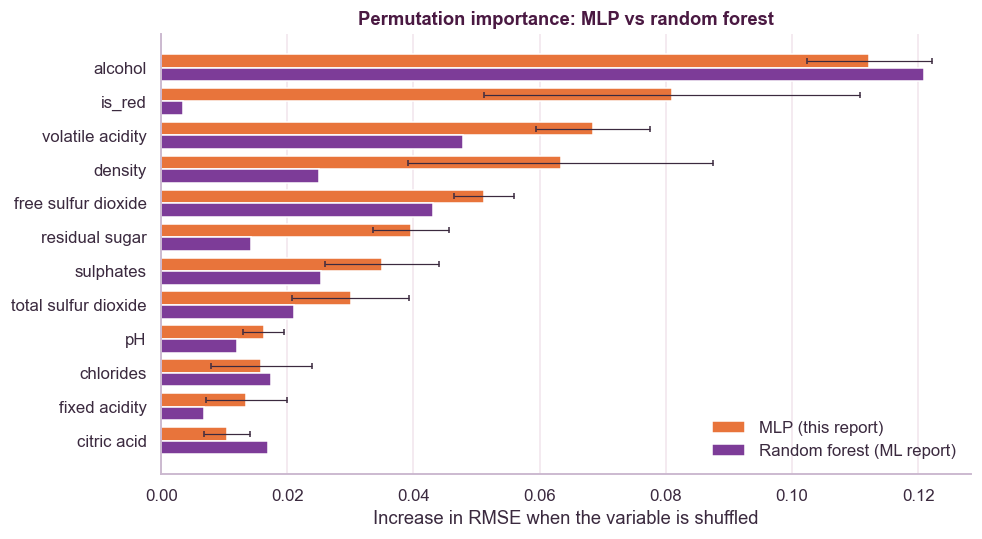

Spearman correlation of the two rankings: 0.46


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
pos = np.arange(len(both))
ax.barh(pos - 0.2, both["MLP"], 0.4, xerr=both["MLP std"], color=ORANGE, label="MLP (this report)",
        error_kw=dict(ecolor=INK, lw=0.8, capsize=2))
ax.barh(pos + 0.2, both["Random forest"], 0.4, color=PURPLE, label="Random forest (ML report)")
ax.set_yticks(pos)
ax.set_yticklabels(both.index)
ax.invert_yaxis()
ax.set_xlabel("Increase in RMSE when the variable is shuffled")
ax.set_title("Permutation importance: MLP vs random forest")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "feature_importance_mlp_vs_rf.png")
plt.show()

print("Spearman correlation of the two rankings: %.2f" % both["MLP"].corr(both["Random forest"], method="spearman"))

## Summary

* Alcohol is the most important variable for both models, and volatile acidity and free sulfur
  dioxide are also in the top 5 for both.
* The big difference is `is_red`: it is the second most important variable for the network, but
  the random forest almost does not use it. The network learns different relations for red and
  white wines and uses the flag to switch between them. When we shuffle `is_red`, a white wine can
  get the red flag, and the network then applies the "red" relations to it. The random forest can
  get the same information from other variables (for example total sulfur dioxide, which is very
  different between red and white wines).
* The network also gives more importance to density and residual sugar. Density depends almost
  completely on sugar and alcohol, and the network can combine these three variables linearly.
* The two rankings are only moderately similar (Spearman correlation 0.46): the importance depends
  on the model, not only on the data.